# Fase 5 — Avaliação

O objetivo desta fase é medir o modelo final **pela lente dos critérios de sucesso de negócio definidos na Fase 1**, e não apenas por métricas estatísticas. Checklist do guia:

1. Avaliar se os resultados respondem à meta
2. Revisar falhas no processo
3. Determinar: implementar ou iterar?

Este é o único notebook que usa o conjunto de teste (1.409 clientes que o modelo nunca viu). Ele é usado uma única vez, com o modelo e o limiar já fechados na Fase 4.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import (roc_auc_score, roc_curve, recall_score, precision_score, f1_score,
                             accuracy_score, confusion_matrix)
from sklearn.inspection import permutation_importance

RAIZ = Path("..").resolve()
sys.path.append(str(RAIZ))
from src.negocio import PREMISSAS, retorno_campanha

sns.set_theme(style="whitegrid")
COR = "#2f6fab"

modelo = joblib.load(RAIZ / "models" / "modelo_churn.joblib")
config = json.load(open(RAIZ / "models" / "config_modelo.json", encoding="utf-8"))
LIMIAR = config["limiar"]

teste = pd.read_csv(RAIZ / "data" / "processed" / "teste.csv")
X_teste = teste[config["atributos_numericos"] + config["atributos_categoricos"]]
y_teste = teste["Churn"]

print(f"Modelo: {config['modelo']} {config['parametros']}")
print(f"Limiar de decisão: {LIMIAR}")
print(f"Conjunto de teste: {len(teste):,} clientes, {int(y_teste.sum())} cancelamentos")

Modelo: Regressão logística {'modelo__C': 1}
Limiar de decisão: 0.21
Conjunto de teste: 1,409 clientes, 374 cancelamentos


## 1. Os resultados respondem à meta?

### 1.1 Desempenho técnico no conjunto de teste

In [2]:
prob = modelo.predict_proba(X_teste)[:, 1]
contatar = prob >= LIMIAR

metricas = pd.DataFrame({
    "teste": {
        "ROC-AUC": roc_auc_score(y_teste, prob),
        "Recall (cancelou)": recall_score(y_teste, contatar),
        "Precisão (cancelou)": precision_score(y_teste, contatar),
        "F1 (cancelou)": f1_score(y_teste, contatar),
        "Acurácia": accuracy_score(y_teste, contatar),
        "Fração da base contatada": contatar.mean(),
    }
}).round(4)
metricas["validação cruzada (Fase 4)"] = [config["roc_auc_validacao"], config["recall_validacao"], None, None, None, None]
metricas

,teste,validação cruzada (Fase 4)
ROC-AUC,0.8427,0.8465
Recall (cancelou),0.8476,0.8515
Precisão (cancelou),0.4810,NaN
F1 (cancelou),0.6137,NaN
Acurácia,0.7168,NaN
Fração da base contatada,0.4677,NaN


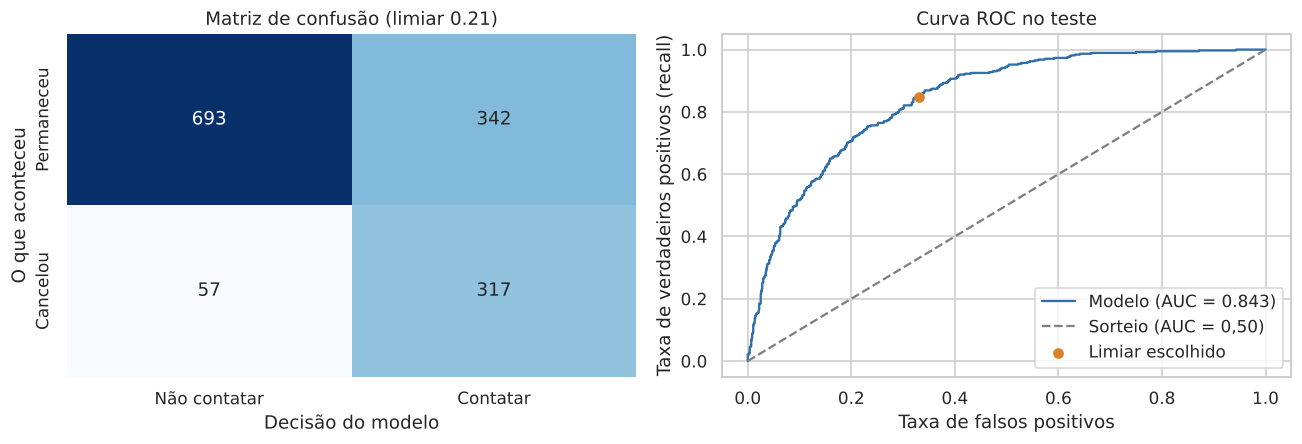

Cancelamentos alcançados pela campanha: 317 de 374
Cancelamentos não alcançados:           57
Contatos em clientes que não sairiam:   342
Clientes corretamente não contatados:   693


In [3]:
matriz = confusion_matrix(y_teste, contatar)
vn, fp, fn, vp = matriz.ravel()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
sns.heatmap(matriz, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax1,
            xticklabels=["Não contatar", "Contatar"], yticklabels=["Permaneceu", "Cancelou"])
ax1.set_xlabel("Decisão do modelo")
ax1.set_ylabel("O que aconteceu")
ax1.set_title(f"Matriz de confusão (limiar {LIMIAR})")

fpr, tpr, _ = roc_curve(y_teste, prob)
ax2.plot(fpr, tpr, color=COR, label=f"Modelo (AUC = {roc_auc_score(y_teste, prob):.3f})")
ax2.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Sorteio (AUC = 0,50)")
ax2.scatter(fp / (fp + vn), vp / (vp + fn), color="#d9822b", zorder=3, label="Limiar escolhido")
ax2.set_xlabel("Taxa de falsos positivos")
ax2.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax2.set_title("Curva ROC no teste")
ax2.legend()
plt.tight_layout()
plt.show()

print(f"Cancelamentos alcançados pela campanha: {vp} de {vp + fn}")
print(f"Cancelamentos não alcançados:           {fn}")
print(f"Contatos em clientes que não sairiam:   {fp}")
print(f"Clientes corretamente não contatados:   {vn}")

In [4]:
# Intervalo de 95% por bootstrap: o teste tem 1.409 clientes, então as métricas têm margem de erro.
rng = np.random.default_rng(42)
y_array = y_teste.to_numpy()
aucs, recalls = [], []
for _ in range(1000):
    i = rng.integers(0, len(y_array), len(y_array))
    aucs.append(roc_auc_score(y_array[i], prob[i]))
    recalls.append(recall_score(y_array[i], contatar[i]))
print(f"ROC-AUC: {roc_auc_score(y_teste, prob):.3f}  (intervalo de 95%: {np.percentile(aucs, 2.5):.3f} a {np.percentile(aucs, 97.5):.3f})")
print(f"Recall:  {recall_score(y_teste, contatar):.3f}  (intervalo de 95%: {np.percentile(recalls, 2.5):.3f} a {np.percentile(recalls, 97.5):.3f})")

ROC-AUC: 0.843  (intervalo de 95%: 0.821 a 0.863)
Recall:  0.848  (intervalo de 95%: 0.810 a 0.883)


**Leitura dos resultados técnicos**

- **ROC-AUC de 0,843** no teste, contra 0,847 na validação cruzada. A proximidade indica que não houve sobreajuste. Mesmo o limite inferior do intervalo de 95% (0,821) fica acima da meta de 0,80.
- **Recall de 84,8%:** a campanha alcançaria 317 dos 374 clientes que cancelaram. O limite inferior do intervalo (81,0%) também supera a meta de 70%.
- **Precisão de 48,1%:** dos 659 clientes marcados para contato, 317 realmente cancelariam. Cerca de um em cada dois contatos seria feito em quem não ia sair. Esse é o preço do recall alto, aceito de forma consciente na Fase 4.
- **Acurácia de 71,7%**, abaixo dos 73,5% de quem simplesmente dissesse "ninguém cancela". Isso não é um defeito: o limiar foi escolhido para encontrar cancelamentos, e não para maximizar acertos totais. É o motivo de a acurácia não ter sido adotada como critério.

### 1.2 Impacto de negócio: simulação da campanha

A simulação compara três estratégias nos 1.409 clientes de teste, com as premissas da Fase 1 (custo de $ 50 por contato, 30% de sucesso da oferta e 12 mensalidades preservadas por cliente retido).

In [5]:
mensalidade = teste["MonthlyCharges"]
estrategias = {
    "Não fazer campanha": np.zeros(len(teste), dtype=bool),
    "Contatar toda a base": np.ones(len(teste), dtype=bool),
    "Contatar quem o modelo indica": contatar,
}
simulacao = pd.DataFrame({nome: retorno_campanha(y_teste, sel, mensalidade) for nome, sel in estrategias.items()}).T
simulacao["retorno_por_contato"] = (simulacao["retorno_liquido"] / simulacao["clientes_contatados"].replace(0, np.nan)).round(2)
simulacao

,clientes_contatados,churners_alcancados,receita_preservada,custo_campanha,retorno_liquido,retorno_por_contato
Não fazer campanha,0.0,0.0,0.00,0.0,0.00,NaN
Contatar toda a base,1409.0,374.0,97973.64,70450.0,27523.64,19.53
Contatar quem o modelo indica,659.0,317.0,85345.92,32950.0,52395.92,79.51


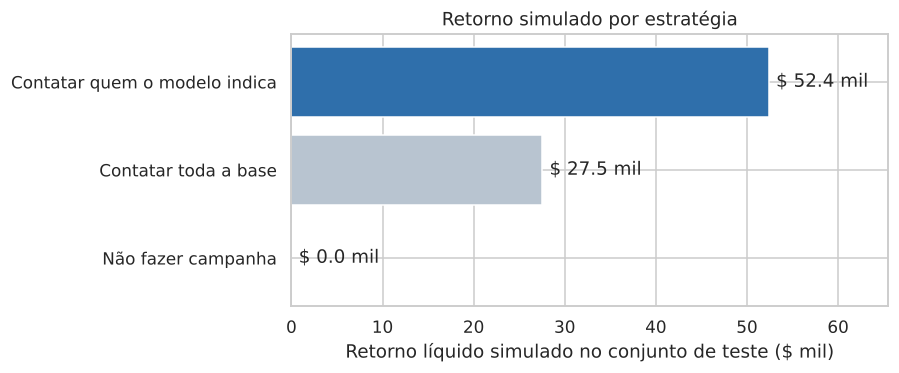

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.2))
valores = simulacao["retorno_liquido"] / 1000
ax.barh(valores.index, valores.values, color=["#b8c4d0", "#b8c4d0", COR])
for i, v in enumerate(valores.values):
    ax.text(v + 0.8, i, f"$ {v:,.1f} mil", va="center")
ax.set_xlim(0, valores.max() * 1.25)
ax.set_xlabel("Retorno líquido simulado no conjunto de teste ($ mil)")
ax.set_title("Retorno simulado por estratégia")
plt.show()

### 1.3 Sensibilidade às premissas

As premissas não vêm de dados reais. A tabela abaixo repete a simulação variando a taxa de sucesso da oferta e o custo por contato, para verificar se a conclusão depende dos valores escolhidos. Cada célula mostra a **vantagem da campanha direcionada sobre contatar toda a base**, em $.

In [7]:
linhas = {}
for taxa in [0.10, 0.20, 0.30, 0.40, 0.50]:
    linha = {}
    for custo in [25, 50, 100, 150]:
        modelo_ret = retorno_campanha(y_teste, contatar, mensalidade, taxa_sucesso=taxa, custo_contato=custo)["retorno_liquido"]
        todos_ret = retorno_campanha(y_teste, estrategias["Contatar toda a base"], mensalidade, taxa_sucesso=taxa, custo_contato=custo)["retorno_liquido"]
        linha[f"custo $ {custo}"] = round(modelo_ret - todos_ret)
    linhas[f"sucesso {taxa:.0%}"] = linha
vantagem = pd.DataFrame(linhas).T
vantagem

,custo $ 25,custo $ 50,custo $ 100,custo $ 150
sucesso 10%,14541,33291,70791,108291
sucesso 20%,10332,29082,66582,104082
sucesso 30%,6122,24872,62372,99872
sucesso 40%,1913,20663,58163,95663
sucesso 50%,-2296,16454,53954,91454


In [8]:
linhas = {}
for taxa in [0.10, 0.20, 0.30, 0.40, 0.50]:
    linha = {}
    for custo in [25, 50, 100, 150]:
        linha[f"custo $ {custo}"] = round(retorno_campanha(y_teste, contatar, mensalidade, taxa_sucesso=taxa, custo_contato=custo)["retorno_liquido"])
    linhas[f"sucesso {taxa:.0%}"] = linha
print("Retorno líquido da campanha direcionada ($), com o limiar fixo da Fase 4:")
pd.DataFrame(linhas).T

Retorno líquido da campanha direcionada ($), com o limiar fixo da Fase 4:


,custo $ 25,custo $ 50,custo $ 100,custo $ 150
sucesso 10%,11974,-4501,-37451,-70401
sucesso 20%,40422,23947,-9003,-41953
sucesso 30%,68871,52396,19446,-13504
sucesso 40%,97320,80845,47895,14945
sucesso 50%,125768,109293,76343,43393


**Leitura dos resultados de negócio**

Com as premissas base, a campanha direcionada rende **$ 52,4 mil** nos 1.409 clientes de teste, contra $ 27,5 mil ao contatar toda a base. É quase o dobro do retorno com menos da metade dos contatos (659 em vez de 1.409), e o retorno por contato sobe de $ 19,53 para $ 79,51.

A análise de sensibilidade mostra até onde essa conclusão se sustenta:

- **Direcionar é melhor do que contatar todos em 19 dos 20 cenários.** A exceção é a oferta barata e muito eficaz ($ 25 e 50% de sucesso), em que vale a pena contatar a base inteira.
- **A campanha em si dá prejuízo em 6 dos 20 cenários**, todos com oferta cara ou pouco eficaz (por exemplo, 10% de sucesso com custo de $ 50 ou mais). Nesses casos o limiar de 0,21, calculado para as premissas base, estaria baixo demais e teria de ser recalculado.

Ou seja, o modelo cumpre seu papel de direcionar a campanha, mas a viabilidade financeira depende da taxa real de sucesso da oferta e do seu custo, que o projeto não tem como medir com os dados atuais.

### 1.4 Os fatores de risco fazem sentido comercial?

A importância por permutação mede quanto a ROC-AUC do modelo cai quando os valores de um atributo são embaralhados no conjunto de teste. Quanto maior a queda, mais o modelo depende daquele atributo.

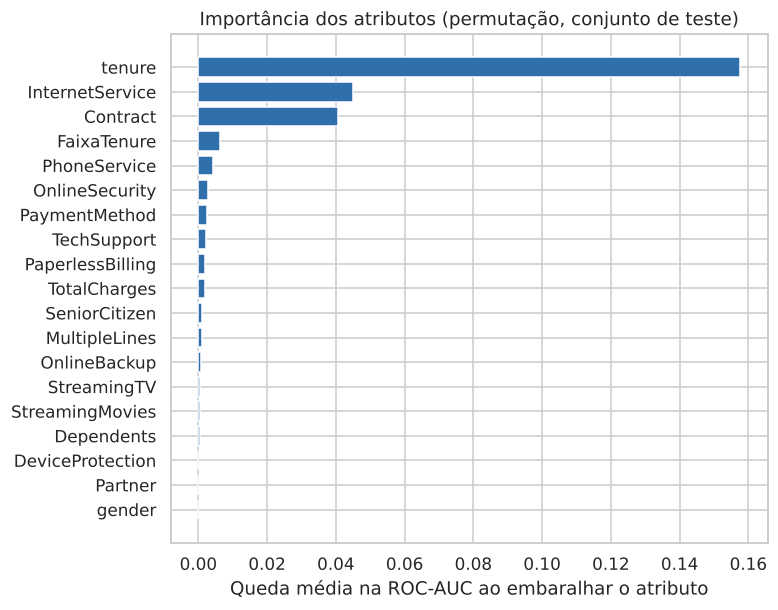

,queda_na_roc_auc
tenure,0.1577
InternetService,0.0451
Contract,0.0406
FaixaTenure,0.0062
PhoneService,0.0043
OnlineSecurity,0.0027
PaymentMethod,0.0025
TechSupport,0.0023


In [9]:
importancia = permutation_importance(modelo, X_teste, y_teste, scoring="roc_auc", n_repeats=20, random_state=42)
imp = pd.Series(importancia.importances_mean, index=X_teste.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(imp.index, imp.values, color=COR)
ax.set_xlabel("Queda média na ROC-AUC ao embaralhar o atributo")
ax.set_title("Importância dos atributos (permutação, conjunto de teste)")
plt.show()

imp.sort_values(ascending=False).round(4).head(8).to_frame("queda_na_roc_auc")

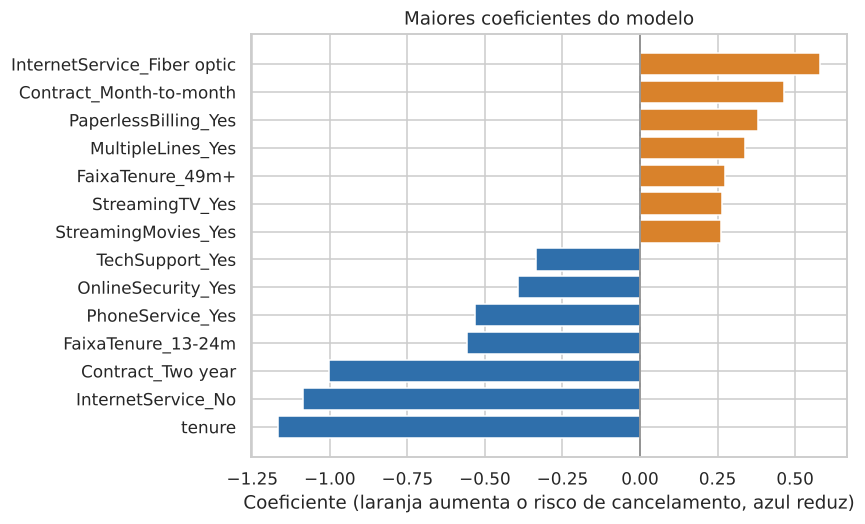

Coeficientes dos atributos sensíveis:
gender_Male          0.018
SeniorCitizen_Yes    0.153


In [10]:
# Coeficientes da regressão logística: sinal positivo aumenta o risco, negativo reduz.
nomes = modelo.named_steps["preprocessamento"].get_feature_names_out()
coef = pd.Series(modelo.named_steps["modelo"].coef_[0], index=[n.split("__", 1)[1] for n in nomes])
ordenados = coef.sort_values()
extremos = pd.concat([ordenados.head(7), ordenados.tail(7)])

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(extremos.index, extremos.values, color=[COR if v < 0 else "#d9822b" for v in extremos.values])
ax.axvline(0, color="gray", linewidth=1)
ax.set_xlabel("Coeficiente (laranja aumenta o risco de cancelamento, azul reduz)")
ax.set_title("Maiores coeficientes do modelo")
plt.show()

print("Coeficientes dos atributos sensíveis:")
print(coef[[i for i in coef.index if i.startswith(("gender", "SeniorCitizen"))]].round(3).to_string())

In [11]:
# Taxa real de cancelamento por faixa de risco prevista
teste_av = teste.assign(probabilidade=prob)
teste_av["decil"] = pd.qcut(teste_av["probabilidade"], 10, labels=range(1, 11))
decis = teste_av.groupby("decil", observed=True).agg(
    clientes=("Churn", "size"), cancelamentos=("Churn", "sum"), taxa_real=("Churn", "mean"),
    prob_media_prevista=("probabilidade", "mean"),
).round(3)
decis["cancelamentos_acumulados_%"] = (decis["cancelamentos"][::-1].cumsum()[::-1] / decis["cancelamentos"].sum() * 100).round(1)
decis.sort_index(ascending=False)

,clientes,cancelamentos,taxa_real,prob_media_prevista,cancelamentos_acumulados_%
decil,,,,,
10,141,105,0.745,0.749,28.1
9,141,81,0.574,0.589,49.7
8,141,60,0.426,0.457,65.8
7,141,42,0.298,0.338,77.0
6,140,39,0.279,0.232,87.4
5,141,21,0.149,0.153,93.0
4,141,16,0.113,0.084,97.3
3,141,6,0.043,0.044,98.9
2,141,2,0.014,0.021,99.5


**Leitura dos fatores de risco**

Os atributos de que o modelo mais depende são o **tempo de casa** (`tenure`), o **tipo de internet** e o **tipo de contrato**. Os coeficientes apontam na direção esperada:

| Aumentam o risco | Reduzem o risco |
|---|---|
| Internet por fibra óptica | Mais tempo de casa |
| Contrato mensal | Contrato de dois anos |
| Fatura digital | Não ter internet |
| Múltiplas linhas e streaming | Segurança online e suporte técnico |

Isso confirma as hipóteses H1 (contrato), H2 (tempo de casa), H3 (fibra) e H5 (serviços de suporte) da Fase 2. Sobre a H6, o cheque eletrônico é a única forma de pagamento com coeficiente positivo, embora pequeno. A H4 (mensalidade) não é avaliada diretamente, porque `MonthlyCharges` saiu do modelo na Fase 4; seu efeito aparece por meio dos serviços que encarecem a conta, como fibra e streaming. Os coeficientes de `FaixaTenure` não devem ser lidos isoladamente, pois atuam em conjunto com `tenure`.

**Atributos sensíveis:** o gênero tem coeficiente praticamente nulo (0,02) e ser idoso tem peso pequeno (0,15). O modelo não se apoia nesses atributos.

**Faixas de risco:** entre os 10% de clientes com maior risco previsto, 74,5% de fato cancelaram; entre os 10% de menor risco, 1,4%. Os três décimos de maior risco concentram 65,8% de todos os cancelamentos. As probabilidades previstas ficam próximas das taxas reais em cada faixa, o que indica um modelo bem calibrado.

O critério CN3 (fatores com sentido comercial) é considerado atendido.

### 1.5 Conferência com os critérios da Fase 1

In [12]:
auc_teste = roc_auc_score(y_teste, prob)
recall_teste = recall_score(y_teste, contatar)
ret_modelo = simulacao.loc["Contatar quem o modelo indica", "retorno_liquido"]
ret_todos = simulacao.loc["Contatar toda a base", "retorno_liquido"]

criterios = pd.DataFrame([
    ["CN1", "Alcançar pelo menos 70% dos clientes que cancelariam", f"{recall_teste:.1%}", recall_teste >= 0.70],
    ["CN2", "Retorno líquido positivo e maior do que contatar toda a base", f"$ {ret_modelo:,.0f} contra $ {ret_todos:,.0f}", ret_modelo > 0 and ret_modelo > ret_todos],
    ["CT1", "ROC-AUC ≥ 0,80 no teste", f"{auc_teste:.3f}", auc_teste >= 0.80],
    ["CT2", "Recall ≥ 0,70 no teste, no limiar escolhido", f"{recall_teste:.3f}", recall_teste >= 0.70],
    ["CT3", "Teste próximo da validação cruzada (diferença de ROC-AUC até 0,02)", f"{auc_teste:.3f} contra {config['roc_auc_validacao']:.3f}", abs(auc_teste - config["roc_auc_validacao"]) <= 0.02],
], columns=["critério", "descrição", "resultado", "atendido"]).set_index("critério")
pd.set_option("display.max_colwidth", 100)
criterios

,descrição,resultado,atendido
critério,,,
CN1,Alcançar pelo menos 70% dos clientes que cancelariam,84.8%,True
CN2,Retorno líquido positivo e maior do que contatar toda a base,"$ 52,396 contra $ 27,524",True
CT1,"ROC-AUC ≥ 0,80 no teste",0.843,True
CT2,"Recall ≥ 0,70 no teste, no limiar escolhido",0.848,True
CT3,"Teste próximo da validação cruzada (diferença de ROC-AUC até 0,02)",0.843 contra 0.847,True


Todos os critérios definidos na Fase 1 foram atendidos no conjunto de teste, incluindo o CN3, avaliado na seção anterior.

## 2. Revisão do processo

Pontos fracos e limitações identificados ao revisar as fases anteriores:

| # | Ponto | Consequência |
|---|---|---|
| R1 | **As premissas financeiras não foram validadas.** Custo da oferta, taxa de sucesso e horizonte de receita são suposições | O retorno em dólares é uma simulação. O limiar de 0,21 depende dessas premissas |
| R2 | **O modelo indica quem tende a sair, não quem responde à oferta.** A simulação supõe a mesma taxa de sucesso para todos | Parte dos contatos pode ir para clientes que sairiam de qualquer forma ou que ficariam sem a oferta |
| R3 | **A base é uma fotografia sem datas.** Não foi possível testar o modelo em um período posterior ao do treino | O desempenho real ao longo do tempo é desconhecido |
| R4 | **A redundância entre atributos só foi percebida na modelagem**, pela inspeção dos coeficientes | Custou uma iteração. A verificação poderia ter sido feita na Fase 2 |
| R5 | **Os fatores de risco são associações, não causas** | Mudar o contrato de um cliente não garante que o risco dele caia |
| R6 | **Um único conjunto de teste, com 1.409 clientes** | As métricas têm margem de erro, mostrada nos intervalos de 95% |

Nenhuma dessas limitações invalida o modelo como ferramenta para ordenar clientes por risco. As limitações R1 e R2 afetam diretamente a estimativa de retorno financeiro.

## 3. Decisão: implementar ou iterar?

**Decisão: implementar, em formato de piloto controlado.**

- O modelo atende a todos os critérios técnicos e de negócio da Fase 1, e novas iterações de modelagem trariam pouco ganho: os quatro algoritmos testados chegaram praticamente ao mesmo desempenho.
- O que falta saber (custo real e taxa real de sucesso da oferta) não pode ser descoberto com mais modelagem. Só uma campanha real, com um grupo de controle que não recebe a oferta, pode medir isso.

O plano do piloto, o monitoramento e as lições aprendidas estão na Fase 6.